# Alaska / North Pacific domains

Two domains over the same region at a common ~1/10-degree-equivalent resolution.

- **`alaska_big`** — an oblique-Mercator swath following the arc of the Aleutian
  chain, from the southern tip of Kamchatka across the North Pacific to the
  Oregon coast, and north over the Bering Strait into the Chukchi. Its southern
  edge is pushed well out into open water so the Alaskan Stream, the Alaska Gyre
  and the Gulf of Alaska are interior rather than clipped against the boundary.
- **`alaska_small`** — azimuthal equidistant, north-up, centred on the Bering
  Strait.

## Why `alaska_big` is built the way it is

Naming two corners does not determine a domain. At these latitudes the *curve*
between them is the whole design: the geodesic from southern Kamchatka to the
Washington coast bulges poleward onto the Alaska Peninsula, while a rhumb line
between the same two points passes some six degrees further south. Everything
the domain is meant to contain lives in that gap.

In an oblique Mercator, lines of constant `y` are small circles sharing an axis
with the central great circle — so the southern edge is always a small circle
through the two corners, and three points determine a circle. Naming a third
control point out in the open Pacific pins the edge exactly. That turns the
design knob into the one that actually matters — *how far south does the edge
dip* — instead of a rotation angle whose effect has to be found by trial.

The geometry lives in `omerc_swath.py`; this notebook is the design surface.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# This domain crosses the antimeridian, and the mom6_forge copy embedded under
# CrocoDash computes dx from a raw np.diff of longitude. At the dateline two
# adjacent supergrid nodes read 179.99 and -179.99, so that diff is ~-360
# degrees instead of ~0.02, giving dx ~ -25,900 km over the seam column. The fix
# (wrap the difference into (-180, 180] first) lives only on this branch so far,
# so put it ahead of the embedded copy on the path.
MOM6_FORGE_FIX = Path("/glade/u/home/manishrv/documents/croc/regional_mom_workflows"
                      "/mom6_forge-worktrees/fix-polar-dx-antimeridian-wrap")
if MOM6_FORGE_FIX.is_dir():
    sys.path.insert(0, str(MOM6_FORGE_FIX))

from CrocoDash.grid import Grid
import mom6_forge
from mom6_forge._supergrid import SupergridBase

import omerc_swath as osw

OUT_ROOT = Path(__file__).parent if "__file__" in dir() else Path.cwd()
OUT_ROOT = OUT_ROOT / "alaska_grids"

# Verify the wrap fix is the one that actually loaded, rather than trusting the
# path order: two nodes either side of the dateline must come out ~1.1 km apart
# at 60 N, not ~-25,900 km.
_dx, _ = SupergridBase._calc_dx_dy(np.array([[179.99, -179.99]]),
                                   np.array([[60.0, 60.0]]))
assert 0.0 < _dx[0, 0] < 5e3, (
    f"mom6_forge lacks the antimeridian dx wrap fix (seam dx = {_dx[0, 0]:.1f} m); "
    f"loaded from {mom6_forge.__file__}")
print("mom6_forge:", mom6_forge.__file__)
print(f"seam dx check: {_dx[0, 0]:.1f} m across the dateline -- wrap fix present")
print("output root:", OUT_ROOT)

LAND_10M = cfeature.NaturalEarthFeature("physical", "land", "10m")

# Places used as checks, so "did we get it?" is printed rather than eyeballed.
LANDMARKS = {
    "Cape Lopatka (S tip Kamchatka)": (50.86, 156.66),
    "Aleutians: Adak": (51.88, -176.65),
    "GoA: Kodiak": (57.79, -152.41),
    "GoA: Prince William Sd": (60.30, -147.00),
    "GoA: Yakutat": (59.55, -139.73),
    "Vancouver BC": (49.28, -123.12),
    "Anchorage": (61.22, -149.90),
    "Bering Strait": (65.80, -169.00),
    "Cape Dezhnev (E tip Chukotka)": (66.08, -169.65),
    "Cape Prince of Wales (Seward)": (65.59, -168.09),
}

mom6_forge: /glade/u/home/manishrv/documents/croc/regional_mom_workflows/mom6_forge-worktrees/fix-polar-dx-antimeridian-wrap/mom6_forge/__init__.py
seam dx check: 1111.9 m across the dateline -- wrap fix present
output root: /glade/u/home/manishrv/documents/croc/dev/tutorial_grid_tests/alaska_grids


## Resolution

Both domains share a `resolution_m` matched to a 1/10-degree lat/lon grid over
this latitude band. A naive `111_320 * 0.1` describes only the meridional
spacing and ignores the `cos(lat)` shrinkage of zonal spacing, which badly
overstates cell area this far north — at 62 N the zonal spacing is under half
the meridional. Matching the *mean cell area* gives one isotropic number.

Note this is the spacing in the **projected plane**. `Grid.from_projection`
divides it by the projection's scale factor, so a value handed straight in comes
out *finer* than requested by exactly that factor. For `alaska_big` the scale
factor is ~1.9 across the domain, so passing 7826 m gave ~4.2 km cells rather
than the ~7.9 km intended — a 1/17-degree grid wearing a 1/10-degree label.

So `alaska_big` pre-multiplies by its own measured median scale factor, below,
and `resolution_m` here is used directly only by `alaska_small`, whose azimuthal
equidistant frame has a scale factor of ~1.

In [2]:
RESOLUTION_DEG = 0.1
LAT_MIN, LAT_MAX = 45.0, 75.0

resolution_m = osw.resolution_m_for(RESOLUTION_DEG, LAT_MIN, LAT_MAX)
print(f"{RESOLUTION_DEG} deg meridional spacing : {111_320.0 * RESOLUTION_DEG:8.1f} m")
print(f"resolution_m (sqrt mean area)  : {resolution_m:8.1f} m")

0.1 deg meridional spacing :  11132.0 m
resolution_m (sqrt mean area)  :   7826.5 m


## `alaska_big` — the design knobs

Four numbers define the domain. Change any of them and re-run the preview cell;
it costs a fraction of a second because it only traces the four edges, never
builds a mesh.

| knob | meaning |
|---|---|
| `SW_ANCHOR` | southwest corner — southern tip of Kamchatka |
| `SE_ANCHOR` | southeast corner — how far down the North American coast |
| `CONTROL` | how far south the southern edge dips, out in the open Pacific |
| `NORTH_MARGIN_M` | how far past the Bering Strait the north edge sits |

Anchors must be on **land**; the preview checks that. `SE_ANCHOR` at 45.0 N puts
the southeast corner on the Oregon coast, just past Washington's southern border
at 46.3 N. Pushing it further south is close to free — it *lowers* `k` and the
cell count, because the southern edge flattens relative to the frame.

In [3]:
SW_ANCHOR = (51.00, 156.80)     # southern tip of Kamchatka
SE_ANCHOR = (45.00, -123.85)    # Oregon coast, just south of Washington
CONTROL = (48.00, -160.00)      # southern edge passes through here, open Pacific
NORTH_OF = LANDMARKS["Bering Strait"]
NORTH_MARGIN_M = 500e3

PROBE_LONS = [175.0, -175.0, -165.0, -155.0, -145.0, -135.0]
GAP_LON = -155.0


def preview(sw=SW_ANCHOR, se=SE_ANCHOR, control=CONTROL,
            north_of=NORTH_OF, north_margin_m=NORTH_MARGIN_M,
            res_m=None, verbose=True):
    """Trace a candidate domain's edges and report it, without building a mesh."""
    res_m = resolution_m if res_m is None else res_m
    for nm, p in [("SW", sw), ("SE", se)]:
        if not osw.is_land(p[1], p[0]):
            print(f"  !! {nm} anchor {p} is in water -- move it onto land")

    made = osw.frame_through(sw, se, control)
    if made is None:
        print("  !! the three points are collinear; the edge is undetermined")
        return None
    crs, info = made
    box = osw.box_for(crs, sw, se, north_of, north_margin_m)
    if box is None:
        print("  !! degenerate extent (north edge below the southern edge?)")
        return None

    lon, lat, (slon, slat), corners = osw.box_outline(
        crs, box["x_min"], box["x_max"], box["y_min"], box["y_max"])
    k, k_finite = osw.scale_spread(crs, lon, lat)
    nx = int((box["x_max"] - box["x_min"]) / res_m)
    ny = int((box["y_max"] - box["y_min"]) / res_m)
    coast = osw.southern_coast_lat(GAP_LON)
    gap_km = (coast - osw.south_edge_at(slon, slat, GAP_LON)) * 111.32

    if verbose:
        print(f"alpha {info['alpha']:.2f} deg, gamma {info['gamma']:.2f} deg, "
              f"central line {info['central_offset_m']/1e3:.0f} km from the edge")
        print(f"anchors share a y line to within {box['anchor_resid_m']:.1f} m")
        print(f"{nx} x {ny} cells ({nx*ny/1e6:.2f} M), k spread {k:.3f}"
              f"{'' if k_finite else '  !! NON-FINITE -- metrics would be zero'}")
        print(f"open water under Alaska at {abs(GAP_LON):.0f} W: {gap_km:.0f} km "
              f"(coast at {coast:.2f} N)")
        print("southern edge:  " + "  ".join(
            f"{abs(w):.0f}{'E' if w > 0 else 'W'} {osw.south_edge_at(slon, slat, w):.1f}N"
            for w in PROBE_LONS))
        for nm, (lo, la) in zip(["SW", "SE", "NW", "NE"], corners):
            l180 = ((lo + 180) % 360) - 180
            print(f"  {nm} ({l180:9.3f}, {la:7.3f})  "
                  f"{'land' if osw.is_land(lo, la) else 'OCEAN'}")
        inside = inside_report(crs, box)
        out = [n for n, v in inside.items() if not v]
        print("landmarks outside: " + (", ".join(out) if out else "none"))
    return dict(crs=crs, info=info, box=box, corners=corners, nx=nx, ny=ny,
                k=k, gap_km=gap_km, lon=lon, lat=lat)


def inside_report(crs, box):
    from pyproj import Transformer
    fwd = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
    out = {}
    for nm, (la, lo) in LANDMARKS.items():
        x, y = fwd.transform(lo, la)
        out[nm] = bool(box["x_min"] <= x <= box["x_max"]
                       and box["y_min"] <= y <= box["y_max"])
    return out


design = preview()

# Rescale so RESOLUTION_DEG means what it says. from_projection divides
# projected spacing by the scale factor, so ask for target * median(k) in the
# plane to land on target on the ground. Measured over the domain interior
# rather than assumed, then previewed again to show the real cell count.
big_resolution_m = osw.resolution_m_for_physical(
    design["crs"], design["box"], resolution_m)
print()
print(f"median scale factor {big_resolution_m / resolution_m:.3f}")
print(f"alaska_big projected spacing {big_resolution_m:.1f} m "
      f"-> ~{resolution_m / 1e3:.2f} km physical cells")
print()
design = preview(res_m=big_resolution_m)

alpha 94.73 deg, gamma 77.13 deg, central line 5247 km from the edge
anchors share a y line to within 0.0 m
1112 x 504 cells (0.56 M), k spread 2.124
open water under Alaska at 155 W: 1130 km (coast at 58.05 N)
southern edge:  175E 49.9N  175W 49.3N  165W 48.6N  155W 47.9N  145W 47.1N  135W 46.2N
  SW (  156.800,  51.000)  land
  SE ( -123.850,  45.000)  land
  NW (  158.736,  67.710)  land
  NE ( -118.084,  66.337)  land
landmarks outside: Cape Lopatka (S tip Kamchatka)

median scale factor 1.871
alaska_big projected spacing 14644.3 m -> ~7.83 km physical cells

alpha 94.73 deg, gamma 77.13 deg, central line 5247 km from the edge
anchors share a y line to within 0.0 m
594 x 269 cells (0.16 M), k spread 2.124
open water under Alaska at 155 W: 1130 km (coast at 58.05 N)
southern edge:  175E 49.9N  175W 49.3N  165W 48.6N  155W 47.9N  145W 47.1N  135W 46.2N
  SW (  156.800,  51.000)  land
  SE ( -123.850,  45.000)  land
  NW (  158.736,  67.710)  land
  NE ( -118.084,  66.337)  land
landm

### Build it

`Grid.from_projection` lays uniform spacing in the projected plane and divides
by the scale factor to get true metrics. The assertion below is not decoration:
a projection whose `get_factors` returns `inf` (an oblique Mercator with
`+no_rot`, for instance) produces **exactly zero** `dx`/`dy` over most of the
grid, silently — no NaN, no warning, and cell area still looks right because it
is derived from lon/lat rather than from the metrics.

In [4]:
def metric_report(grid, label):
    sg = grid._supergrid
    dx, dy = np.asarray(sg.dx), np.asarray(sg.dy)
    area = np.asarray(grid.tarea)
    print(f"{label}: {grid.nx} x {grid.ny} cells")
    print(f"    dx   [{dx.min():9.1f}, {dx.max():9.1f}] m   spread {dx.max()/dx.min():.3f}x")
    print(f"    dy   [{dy.min():9.1f}, {dy.max():9.1f}] m   spread {dy.max()/dy.min():.3f}x")
    print(f"    area [{area.min():.4e}, {area.max():.4e}] m^2  "
          f"spread {area.max()/area.min():.3f}x")
    bad = int((dx <= 0).sum() + (dy <= 0).sum())
    print(f"    non-positive metrics: {bad}"
          + ("  <-- BROKEN" if bad else ""))
    return dx, dy, area


b = design["box"]
alaska_big = Grid.from_projection(
    crs=design["crs"],
    x_min=b["x_min"], x_max=b["x_max"], y_min=b["y_min"], y_max=b["y_max"],
    resolution_m=big_resolution_m,
    name="alaska_big",
)
big_dx, big_dy, big_area = metric_report(alaska_big, "alaska_big")
assert (big_dx > 0).all() and (big_dy > 0).all(), \
    "degenerate metrics -- do not write this grid"

alaska_big: 594 x 269 cells
    dx   [   2607.7,    5537.5] m   spread 2.123x
    dy   [   2612.5,    5543.8] m   spread 2.122x
    area [2.7131e+07, 1.2241e+08] m^2  spread 4.512x
    non-positive metrics: 0


## `alaska_small` — Bering Strait close-up

`Grid.from_center` lays a plain rectangular mesh on an azimuthal equidistant
projection centred at the given point. Centring on the strait itself removes the
tilt an Alaska-Albers version had: EPSG:3338 is centred at 154 W, some 20 degrees
east of here, so a box over the strait came out visibly rotated.

In [5]:
SMALL_LON_MIN, SMALL_LON_MAX = 172.0, 200.0    # 172 E -> 160 W
SMALL_LAT_MIN, SMALL_LAT_MAX = 63.5, 67.5

_center_lon = ((SMALL_LON_MIN + SMALL_LON_MAX) / 2 + 180) % 360 - 180
_center_lat = (SMALL_LAT_MIN + SMALL_LAT_MAX) / 2
_width_m = ((SMALL_LON_MAX - SMALL_LON_MIN) * 111_320.0
            * np.cos(np.deg2rad(_center_lat)))
_height_m = (SMALL_LAT_MAX - SMALL_LAT_MIN) * 111_320.0
print(f"centre ({_center_lat:.2f} N, {_center_lon:.2f} E)  "
      f"{_width_m/1e3:.0f} x {_height_m/1e3:.0f} km")

alaska_small = Grid.from_center(
    center_lat=_center_lat, center_lon=_center_lon,
    width_m=_width_m, height_m=_height_m,
    resolution_m=resolution_m, angle_deg=0.0, name="alaska_small",
)
small_dx, small_dy, small_area = metric_report(alaska_small, "alaska_small")
assert (small_dx > 0).all() and (small_dy > 0).all()

centre (65.50 N, -174.00 E)  1293 x 445 km
alaska_small: 165 x 56 cells
    dx   [   3792.1,    3901.7] m   spread 1.029x
    dy   [   3846.3,    3965.9] m   spread 1.031x
    area [6.1748e+07, 6.1888e+07] m^2  spread 1.002x
    non-positive metrics: 0


## Both domains

Land and coastlines at 10 m — the bare `cfeature.LAND` constant is 110 m, too
coarse to judge where a domain edge falls against a coastline. Corners are
coloured by whether they sit on land.

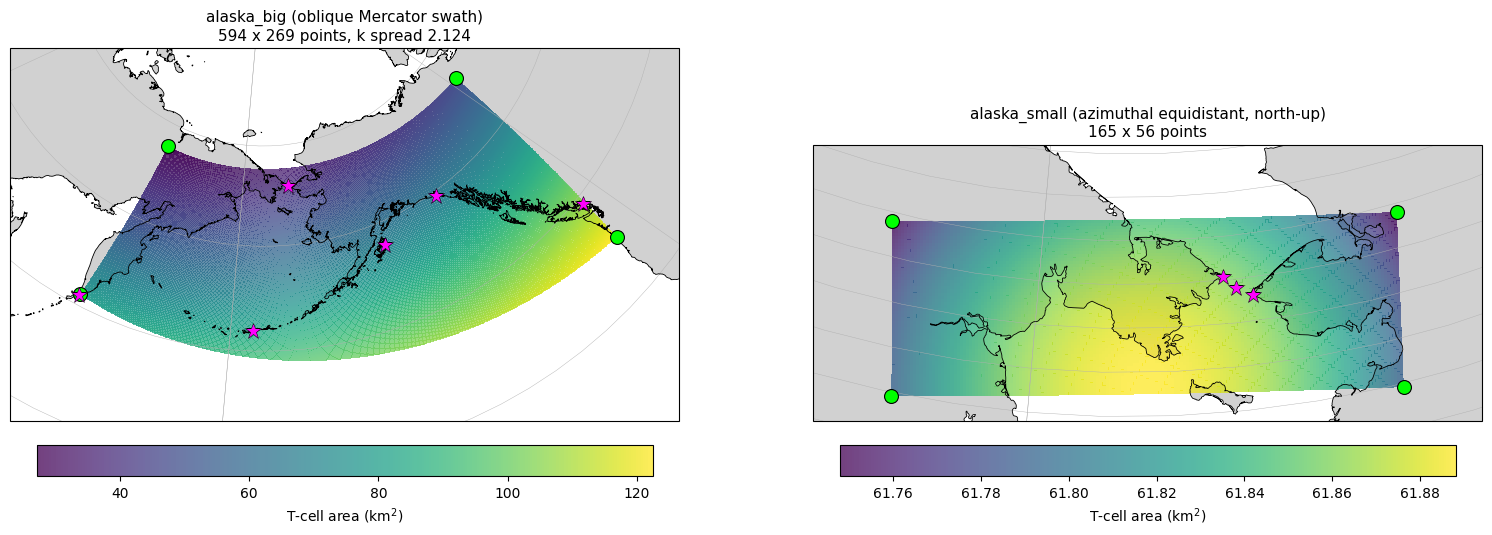

In [6]:
def draw(ax, grid, pad, marks, title):
    ax.add_feature(LAND_10M, facecolor="0.82", edgecolor="none", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.6, zorder=3)
    ax.gridlines(linewidth=0.3)
    # shift to a seam-free branch so min/max actually describe the domain
    lx = np.asarray(grid._supergrid.x) % 360.0
    ly = np.asarray(grid._supergrid.y)
    ax.set_extent([lx.min() - pad, lx.max() + pad,
                   ly.min() - pad / 2, min(ly.max() + pad / 2, 88)],
                  crs=ccrs.PlateCarree())
    mesh = ax.pcolormesh(grid.tlon, grid.tlat, grid.tarea / 1e6,
                         transform=ccrs.PlateCarree(), cmap="viridis",
                         shading="auto", alpha=0.75, zorder=1)
    sx = ((np.asarray(grid._supergrid.x) + 180) % 360) - 180
    sy = np.asarray(grid._supergrid.y)
    for i, j in [(0, 0), (0, -1), (-1, 0), (-1, -1)]:
        a, b_ = float(sx[i, j]), float(sy[i, j])
        ax.plot(a, b_, transform=ccrs.PlateCarree(), marker="o", ms=10,
                mfc="lime" if osw.is_land(a, b_) else "red", mec="black",
                mew=0.8, zorder=6)
    for nm in marks:
        la, lo = LANDMARKS[nm]
        ax.plot(lo, la, transform=ccrs.PlateCarree(), marker="*", ms=12,
                color="magenta", mec="black", mew=0.4, zorder=7)
    plt.colorbar(mesh, ax=ax, orientation="horizontal", fraction=0.05, pad=0.04,
                 label="T-cell area (km$^2$)")
    ax.set_title(title, fontsize=11)


fig, axes = plt.subplots(
    1, 2, figsize=(19, 8),
    subplot_kw={"projection": ccrs.NorthPolarStereo(central_longitude=-175)})
draw(axes[0], alaska_big, 4.0,
     ["Cape Lopatka (S tip Kamchatka)", "Aleutians: Adak", "GoA: Kodiak",
      "GoA: Yakutat", "Vancouver BC", "Bering Strait"],
     f"alaska_big (oblique Mercator swath)\n"
     f"{alaska_big.nx} x {alaska_big.ny} points, k spread {design['k']:.3f}")
draw(axes[1], alaska_small, 1.5,
     ["Bering Strait", "Cape Dezhnev (E tip Chukotka)",
      "Cape Prince of Wales (Seward)"],
     f"alaska_small (azimuthal equidistant, north-up)\n"
     f"{alaska_small.nx} x {alaska_small.ny} points")
plt.show()

## Cell-size structure

`alaska_big` is deliberately not uniform: the oblique Mercator's scale factor is
1 along the central line running down the southern edge and grows northward, and
`from_projection` divides projected spacing by it, so cells shrink toward the
Arctic. This is the same behaviour a plain Mercator lat/lon grid has, but it is
worth seeing rather than assuming — a runaway here is the first sign the frame
is wrong.

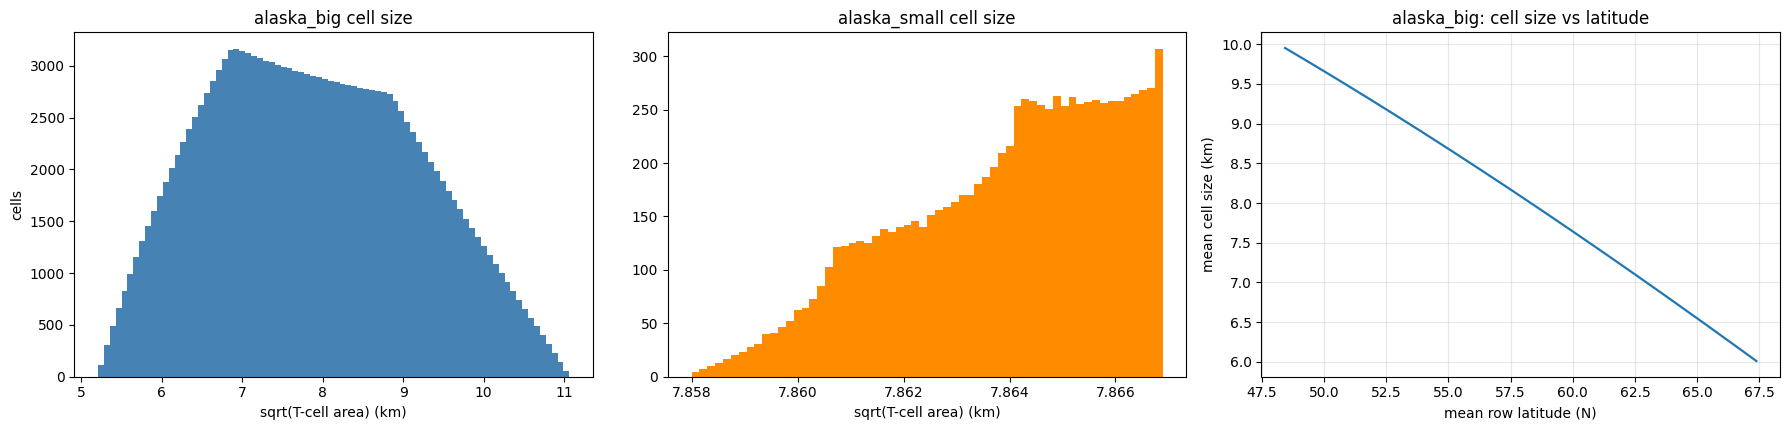

alaska_big    cell size  min  5.21 km  median  7.82 km  max 11.06 km
alaska_small  cell size  min  7.86 km  median  7.86 km  max  7.87 km


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))

axes[0].hist(np.sqrt(big_area.ravel()) / 1e3, bins=80, color="steelblue")
axes[0].set_xlabel("sqrt(T-cell area) (km)")
axes[0].set_ylabel("cells")
axes[0].set_title("alaska_big cell size")

axes[1].hist(np.sqrt(small_area.ravel()) / 1e3, bins=60, color="darkorange")
axes[1].set_xlabel("sqrt(T-cell area) (km)")
axes[1].set_title("alaska_small cell size")

lat_mid = np.asarray(alaska_big.tlat).mean(axis=1)
axes[2].plot(lat_mid, np.sqrt(big_area).mean(axis=1) / 1e3, lw=1.6)
axes[2].set_xlabel("mean row latitude (N)")
axes[2].set_ylabel("mean cell size (km)")
axes[2].set_title("alaska_big: cell size vs latitude")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for nm, area in [("alaska_big", big_area), ("alaska_small", small_area)]:
    s = np.sqrt(area) / 1e3
    print(f"{nm:13s} cell size  min {s.min():5.2f} km  "
          f"median {np.median(s):5.2f} km  max {s.max():5.2f} km")

## Write the supergrids

Each goes to `alaska_grids/<name>/ocean_hgrid.nc`, which is the layout the
CrocoDash case YAMLs in this folder expect.

In [8]:
for grid in [alaska_big, alaska_small]:
    out_dir = OUT_ROOT / grid.name
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / "ocean_hgrid.nc"
    grid.write_supergrid(path=str(out_path), author="manishrv")
    print(f"wrote {out_path}  ({grid.nx} x {grid.ny})")

wrote /glade/u/home/manishrv/documents/croc/dev/tutorial_grid_tests/alaska_grids/alaska_big/ocean_hgrid.nc  (594 x 269)
wrote /glade/u/home/manishrv/documents/croc/dev/tutorial_grid_tests/alaska_grids/alaska_small/ocean_hgrid.nc  (165 x 56)
